# nb5 — Quartz / air / Si (run 3): three-layer fit with six frequency knots per curve

Three-layer transfer-matrix fit of the quartz (1 mm) / air gap / Si (0.4 mm) stack, **run 3**
(`data/ref_3.txt`, `data/quartz_air_silicon_15_min_3.txt`; 3486 points, dt = 33 fs, 115 ps window).

Model (`code/dispersive_grid64.py`, a float64 transcription of `dispersive_multilayer_grid.py`):
each of $n_j(f)$, $\kappa_j(f)$ of quartz and Si is given by its values at **six knots** at
0.20, 0.76, 1.32, 1.88, 2.44, 3.00 THz and interpolated with a natural cubic spline (held at the edge
value outside the band). Air: $n=1$, $\kappa=0$ frozen, $d_{\rm air}$ free (step scale 200 µm).
Loss = MAE + log-cosh of the time-domain residual + hinge penalty $\lambda\,\langle\max(0,-\kappa)\rangle$, $\lambda=1$.
Two stages with Adam (lr $10^{-4}$): stage 1, knots tied (flat $n$, $\kappa$), 15 000 iterations;
stage 2, every knot free, 30 000 iterations.  27 free parameters in stage 2.

Outputs: `figs/fig6_qas_fit.*`, `figs/fig7_qas_nk.*`, `figs/fig8_qas_scans.*` (loss scans, optional panel),
`results/nb5.json`, cache `results/nb5_cache.npz`.

In [1]:
import sys, os, json, time, copy
sys.path.insert(0, '../code')
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_num_threads(int(os.environ.get('NB_THREADS', 2)))
torch.set_default_dtype(torch.float64)

from dispersive_grid64 import Grid, DispersiveMultiLayerGrid, interp_basis, fit, total_loss, data_loss, simulate_dispersive
import paperstyle as ps
ps.apply()

RUN_FULL = False           # False -> load results/nb5_cache.npz if present (skips the 45 000-iteration fit)
CACHE = '../results/nb5_cache.npz'
os.makedirs('../figs', exist_ok=True); os.makedirs('../results', exist_ok=True)

## 1. Data (run 3)

In [2]:
data_ref = np.loadtxt('../data/ref_3.txt')
data_sam = np.loadtxt('../data/quartz_air_silicon_15_min_3.txt')
assert np.allclose(data_ref[:, 0], data_sam[:, 0])
t_r = data_ref[:, 0] - data_ref[0, 0]
x_exp = data_ref[:, 1].astype(np.float64)        # reference pulse
true_x_exp = data_sam[:, 1].astype(np.float64)   # sample pulse
L = len(x_exp)
deltat = (t_r[1] - t_r[0]) * 1e-12

F_LO, F_HI = 0.2, 3.0                            # THz : fit band = knot range
grid = Grid(L, deltat, f_lo=F_LO, f_hi=F_HI)

PREPULSE_PS = 10.0
sigma_noise = float(np.std(true_x_exp[t_r < PREPULSE_PS]))      # pre-pulse std of the sample trace
f_data = np.fft.rfftfreq(L, deltat) / 1e12
S_ref = np.abs(np.fft.rfft(x_exp)); S_sam = np.abs(np.fft.rfft(true_x_exp))
print(f"L = {L}, dt = {deltat*1e15:.1f} fs, window = {t_r[-1]:.1f} ps, df = {grid.deltaf/1e9:.2f} GHz")
print(f"pre-pulse (t < {PREPULSE_PS:.0f} ps) std of the sample trace: sigma = {sigma_noise:.3e}; sample peak {np.abs(true_x_exp).max():.3f}")

L = 3486, dt = 33.0 fs, window = 115.0 ps, df = 2.17 GHz
pre-pulse (t < 10 ps) std of the sample trace: sigma = 9.039e-04; sample peak 1.706


## 2. Model and fit protocol (identical to the reference notebook `QuartzAirSi_grid_Adam_run3.ipynb`)

In [3]:
N_KNOTS, INTERP = 6, 'cubic'
layer_specs = [
    dict(name='quartz', n=1.9820, k=0.0071, d=1.0e-3),
    dict(name='air',    n=1.0,    k=0.0,    d=50e-6, fit_n=False, fit_k=False, d_scale=200e-6),
    dict(name='Si',     n=3.4000, k=0.0054, d=0.4e-3),
]
N_ITERS_FLAT, N_ITERS_DISP = 15000, 30000
LR, K_POS_WEIGHT = 1e-4, 1.0
N_SCALE, K_SCALE = 0.1, 0.005
f_knots = np.linspace(F_LO, F_HI, N_KNOTS)
print('knot frequencies (THz):', np.round(f_knots, 3))

def make_model():
    m = DispersiveMultiLayerGrid(grid, layer_specs, n_knots=N_KNOTS, interp=INTERP, n_scale=N_SCALE, k_scale=K_SCALE)
    m.set_thickness(True)
    return m

knot frequencies (THz): [0.2  0.76 1.32 1.88 2.44 3.  ]


## 3. Stage 1 (knots tied) and stage 2 (knots free)

In [4]:
def run_fits():
    model = make_model(); model.set_dispersion(False)
    t0 = time.time()
    traj_flat = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_FLAT, lr=LR, print_step=2500, label='flat', k_pos_weight=K_POS_WEIGHT)
    t_flat = time.time() - t0
    st_flat = model.state()
    model.load_state(model.state()); model.set_dispersion(True); model.set_thickness(True)
    t0 = time.time()
    traj_disp = fit(model, x_exp, true_x_exp, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='6-knot', k_pos_weight=K_POS_WEIGHT)
    t_disp = time.time() - t0
    st_disp = model.state()
    return traj_flat, traj_disp, st_flat, st_disp, t_flat, t_disp

if RUN_FULL or not os.path.exists(CACHE):
    traj_flat, traj_disp, st_flat, st_disp, t_flat, t_disp = run_fits()
    np.savez(CACHE, **{f'hist_flat_{k}': v for k, v in traj_flat.items()}, **{f'hist_disp_{k}': v for k, v in traj_disp.items()},
             flat_n=st_flat['n'].numpy(), flat_k=st_flat['k'].numpy(), flat_d=st_flat['d'].numpy(),
             disp_n=st_disp['n'].numpy(), disp_k=st_disp['k'].numpy(), disp_d=st_disp['d'].numpy(),
             t_flat=t_flat, t_disp=t_disp)
else:
    z = np.load(CACHE)
    traj_flat = {k: z[f'hist_flat_{k}'] for k in ('n', 'k', 'd', 'loss', 'penalty')}
    traj_disp = {k: z[f'hist_disp_{k}'] for k in ('n', 'k', 'd', 'loss', 'penalty')}
    st_flat = dict(n=torch.tensor(z['flat_n']), k=torch.tensor(z['flat_k']), d=torch.tensor(z['flat_d']))
    st_disp = dict(n=torch.tensor(z['disp_n']), k=torch.tensor(z['disp_k']), d=torch.tensor(z['disp_d']))
    t_flat, t_disp = float(z['t_flat']), float(z['t_disp'])
    print('loaded cache', CACHE)

# models at the two solutions (for plotting / scans)
model_flat = make_model(); model_flat.load_state(st_flat); model_flat.set_dispersion(False)
model = make_model(); model.load_state(st_disp); model.set_dispersion(True)
model.report()
print(f"stage 1: {N_ITERS_FLAT} it. in {t_flat:.0f} s ({1e3*t_flat/N_ITERS_FLAT:.1f} ms/it);  stage 2: {N_ITERS_DISP} it. in {t_disp:.0f} s")
print(f"final loss: stage 1 {traj_flat['loss'][-1]:.4e}, stage 2 {traj_disp['loss'][-1]:.4e}")

loaded cache ../results/nb5_cache.npz
knots (THz): 0.200, 0.760, 1.320, 1.880, 2.440, 3.000
  quartz:  n knots = [1.96516, 1.97118, 1.97266, 1.97454, 1.97804, 1.99166]
           k knots = [+0.00061, +0.00343, +0.00677, +0.00889, +0.01097, +0.01137]      d =   976.63 um   k<0 in band: 0.0 %
     air:  n knots = [1.00000, 1.00000, 1.00000, 1.00000, 1.00000, 1.00000]   (n, k fixed)
           k knots = [+0.00000, +0.00000, +0.00000, +0.00000, +0.00000, +0.00000]      d =   125.87 um   k<0 in band: 0.0 %
      Si:  n knots = [3.39626, 3.39255, 3.39277, 3.39399, 3.39160, 3.38180]
           k knots = [+0.00117, -0.00001, +0.00088, +0.00019, +0.00067, +0.00485]      d =   388.91 um   k<0 in band: 3.9 %
stage 1: 15000 it. in 151 s (10.1 ms/it);  stage 2: 30000 it. in 301 s
final loss: stage 1 3.6223e-03, stage 2 2.9328e-03


## 4. Knot table, derived quantities, comparison with the previous (float32) run-3 result

In [5]:
def simulate(m):
    with torch.no_grad():
        _, y = m.forward(x_exp)
    return y.numpy()

y_flat, y_disp = simulate(model_flat), simulate(model)
mae_flat = float(np.mean(np.abs(true_x_exp - y_flat))); mae_disp = float(np.mean(np.abs(true_x_exp - y_disp)))
st = st_disp
nq, kq, ns, ks = st['n'][0].numpy(), st['k'][0].numpy(), st['n'][2].numpy(), st['k'][2].numpy()
dq, da, ds = (st['d'][j].item() for j in range(3))
print(f"{'f (THz)':>8} | {'n_quartz':>9} {'k_quartz':>9} | {'n_Si':>8} {'k_Si':>10}")
for q in range(N_KNOTS):
    print(f"{f_knots[q]:8.3f} | {nq[q]:9.4f} {kq[q]:9.5f} | {ns[q]:8.4f} {ks[q]:10.6f}")
print(f"\nthicknesses: quartz {dq*1e6:.2f} um, air gap {da*1e6:.2f} um, Si {ds*1e6:.2f} um")
with torch.no_grad():
    n1, k1 = model.nk(np.array([1.0]))
nq1, ns1, kq1, ks1 = n1[0, 0].item(), n1[2, 0].item(), k1[0, 0].item(), k1[2, 0].item()
print(f"n(1 THz): quartz {nq1:.4f}, Si {ns1:.4f};  n*d at 1 THz: quartz {nq1*dq*1e6:.1f} um, Si {ns1*ds*1e6:.1f} um")
print(f"MAE: stage 1 {mae_flat:.4e} = {mae_flat/sigma_noise:.1f} sigma;  stage 2 {mae_disp:.4e} = {mae_disp/sigma_noise:.1f} sigma")

# expected values: run 3 of the float32 reference notebook (QuartzAirSi_grid_Adam_run3.ipynb, cell 15/18 printout)
EXPECTED = dict(quartz_n=[1.96516, 1.97118, 1.97265, 1.97454, 1.97805, 1.99174],
                quartz_k=[0.00061, 0.00343, 0.00676, 0.00890, 0.01097, 0.01137],
                Si_n=[3.39625, 3.39256, 3.39277, 3.39397, 3.39163, 3.38171],
                Si_k=[0.00117, -0.00001, 0.00087, 0.00019, 0.00067, 0.00485],
                d_quartz_um=976.63, d_air_um=125.87, d_Si_um=388.91, loss=2.9327e-3)
ABS_TOL = dict(quartz_k=1e-5, Si_k=1e-5)     # the printed kappa knots have 5 decimals: a relative test alone is meaningless near zero
got = dict(quartz_n=nq, quartz_k=kq, Si_n=ns, Si_k=ks, d_quartz_um=dq*1e6, d_air_um=da*1e6, d_Si_um=ds*1e6, loss=traj_disp['loss'][-1])
deviation = {}
print('\ncomparison with the expected run-3 values (flag: relative deviation > 0.2 %):')
for key, exp in EXPECTED.items():
    e = np.atleast_1d(np.asarray(exp, float)); g = np.atleast_1d(np.asarray(got[key], float))
    rel = 100 * (g - e) / np.where(np.abs(e) > 0, np.abs(e), 1)
    absd = g - e
    flag = (np.abs(rel) > 0.2) & (np.abs(absd) > ABS_TOL.get(key, 0.0))
    deviation[key] = dict(expected=e.tolist(), obtained=g.tolist(), rel_percent=rel.tolist(), abs=absd.tolist(), flagged=bool(flag.any()))
    tag = '  <-- FLAG' if flag.any() else ''
    print(f"  {key:12s} rel. dev. (%) = {np.array2string(rel, precision=3)}   max |abs| = {np.abs(absd).max():.2e}{tag}")

 f (THz) |  n_quartz  k_quartz |     n_Si       k_Si
   0.200 |    1.9652   0.00061 |   3.3963   0.001168
   0.760 |    1.9712   0.00343 |   3.3926  -0.000014
   1.320 |    1.9727   0.00677 |   3.3928   0.000877
   1.880 |    1.9745   0.00889 |   3.3940   0.000187
   2.440 |    1.9780   0.01097 |   3.3916   0.000669
   3.000 |    1.9917   0.01137 |   3.3818   0.004846

thicknesses: quartz 976.63 um, air gap 125.87 um, Si 388.91 um
n(1 THz): quartz 1.9721, Si 3.3922;  n*d at 1 THz: quartz 1926.0 um, Si 1319.3 um
MAE: stage 1 3.5904e-03 = 4.0 sigma;  stage 2 2.9159e-03 = 3.2 sigma

comparison with the expected run-3 values (flag: relative deviation > 0.2 %):
  quartz_n     rel. dev. (%) = [ 0.     0.     0.    -0.    -0.    -0.004]   max |abs| = 7.51e-05
  quartz_k     rel. dev. (%) = [-0.108 -0.019  0.081 -0.085 -0.006  0.016]   max |abs| = 7.61e-06
  Si_n         rel. dev. (%) = [ 0.    -0.    -0.     0.001 -0.001  0.003]   max |abs| = 9.12e-05
  Si_k         rel. dev. (%) = [ -0.2   -

## 5. Loss scans (section 8 of the reference notebook): air gap, and the $n$–$d$ valley of each layer

In [6]:
def loss_at(m):
    with torch.no_grad():
        _, y = m.forward(x_exp)
        return total_loss(y, torch.as_tensor(true_x_exp), m, K_POS_WEIGHT).item()

ms = copy.deepcopy(model); ms.load_state(ms.state())
d0 = st['d'].numpy().copy(); n0 = st['n'].numpy().copy()

t0 = time.time()
d_scan = np.linspace(0, 300e-6, 151); loss_air = []
for v in d_scan:
    ms.d_init[1] = float(v); loss_air.append(loss_at(ms))
ms.d_init[1] = float(d0[1]); loss_air = np.array(loss_air)
i50 = int(np.argmin(np.abs(d_scan - 50e-6)))
print(f"d_air scan: minimum at {d_scan[loss_air.argmin()]*1e6:.1f} um; loss at 50 um = {loss_air[i50]:.3e} vs min {loss_air.min():.3e}")

def landscape(m, j, span=0.03, npts=41):
    nbar = n0[j].mean()
    offs = nbar * np.linspace(-span, span, npts); dd = d0[j] * (1 + np.linspace(-span, span, npts))
    Z = np.zeros((npts, npts))
    for a, o in enumerate(offs):
        m.n_init[j] = torch.tensor(n0[j] + o)
        for b, dv in enumerate(dd):
            m.d_init[j] = float(dv); Z[b, a] = loss_at(m)
    m.n_init[j] = torch.tensor(n0[j]); m.d_init[j] = float(d0[j])
    return nbar + offs, dd, Z

scan = {}
for j, nm in [(0, 'quartz'), (2, 'Si')]:
    nn, dd, Z = landscape(ms, j)
    scan[nm] = dict(n=nn, d=dd, Z=Z)
    print(f"{nm}: loss along the valley (min over d) at mean n = " + ', '.join(f'{nn[i]:.3f}: {Z[:, i].min():.3e}' for i in range(0, 41, 8)))
print(f'scans: {time.time()-t0:.0f} s')

d_air scan: minimum at 126.0 um; loss at 50 um = 1.622e-02 vs min 2.938e-03


quartz: loss along the valley (min over d) at mean n = 1.916: 1.613e-02, 1.940: 7.216e-03, 1.964: 3.781e-03, 1.987: 4.016e-03, 2.011: 7.288e-03, 2.035: 1.417e-02


Si: loss along the valley (min over d) at mean n = 3.290: 7.734e-03, 3.330: 4.189e-03, 3.371: 3.256e-03, 3.412: 3.374e-03, 3.453: 4.172e-03, 3.493: 6.150e-03
scans: 16 s


## 6. Figure 6 — measured and fitted pulse (stage 2), residual, residual spectra

saved ../figs/fig6_qas_fit.png + .pdf  [13.29 x 6.23 cm; placed at 13.3 cm the smallest font prints at 7.01 pt]


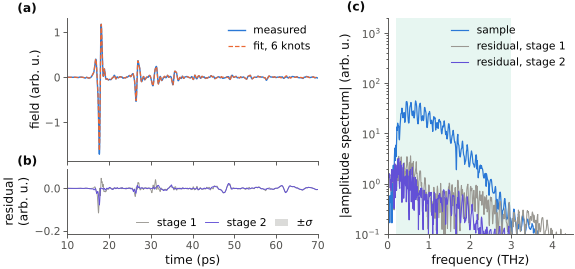

In [7]:
resid_flat = true_x_exp - y_flat; resid_disp = true_x_exp - y_disp
R_flat = np.abs(np.fft.rfft(resid_flat)); R_disp = np.abs(np.fft.rfft(resid_disp))

fig = plt.figure(figsize=ps.figsize(1.0, height_cm=6.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], height_ratios=[2.2, 1], hspace=0.08, wspace=0.32,
                      left=0.09, right=0.99, top=0.95, bottom=0.17)
ax_p = fig.add_subplot(gs[0, 0]); ax_r = fig.add_subplot(gs[1, 0], sharex=ax_p); ax_s = fig.add_subplot(gs[:, 1])

ax_p.plot(t_r, true_x_exp, color=ps.ROLE['sample'], lw=0.9, label='measured')
ax_p.plot(t_r, y_disp, color=ps.ROLE['fit'], lw=0.8, ls='--', label='fit, 6 knots')
ax_p.set_xlim(10, 70); ax_p.set_ylabel('field (arb. u.)'); ax_p.legend(loc='upper right')
plt.setp(ax_p.get_xticklabels(), visible=False)
ax_r.plot(t_r, resid_flat, color=ps.ROLE['stage1'], lw=0.6, label='stage 1')
ax_r.plot(t_r, resid_disp, color=ps.ROLE['residual'], lw=0.6, label='stage 2')
ax_r.axhspan(-sigma_noise, sigma_noise, color=ps.NEUTRAL, alpha=0.35, lw=0, label=r'$\pm\sigma$')
ax_r.set_xlabel('time (ps)'); ax_r.set_ylabel('residual\n(arb. u.)')
rmax = 1.05 * np.abs(resid_disp[(t_r > 10) & (t_r < 70)]).max()
ax_r.set_ylim(-2.6 * rmax, 1.1 * rmax)
ax_r.legend(loc='lower right', ncol=3, columnspacing=0.8, handlelength=1.2, fontsize=7, borderaxespad=0.1)

ax_s.semilogy(f_data, S_sam, color=ps.ROLE['sample'], lw=0.8, label='sample')
ax_s.semilogy(f_data, R_flat, color=ps.ROLE['stage1'], lw=0.7, label='residual, stage 1')
ax_s.semilogy(f_data, R_disp, color=ps.ROLE['residual'], lw=0.7, label='residual, stage 2')
ax_s.axvspan(F_LO, F_HI, color=ps.AQUA, alpha=0.10, lw=0)
ax_s.set_xlim(0, 4.5); ax_s.set_ylim(1e-1, 2e3); ax_s.set_xlabel('frequency (THz)'); ax_s.set_ylabel('|amplitude spectrum| (arb. u.)')
ax_s.legend(loc='upper right')
for a in (ax_p, ax_r, ax_s): ps.despine(a)
ps.panel_label(ax_p, 'a', x=-0.2); ps.panel_label(ax_r, 'b', x=-0.2); ps.panel_label(ax_s, 'c', x=-0.22)
ps.savefig(fig, '../figs/fig6_qas_fit')
plt.show()

## 8. Figure 8 (optional panel) — loss scans: air gap, and $n$-offset vs $d$ for quartz and Si

saved ../figs/fig8_qas_scans.png + .pdf  [13.30 x 4.35 cm; placed at 13.3 cm the smallest font prints at 7.00 pt]


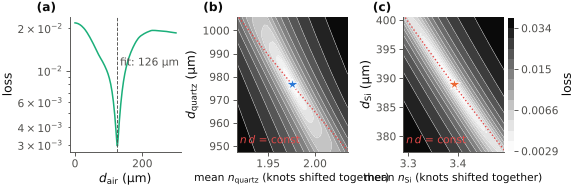

In [8]:
fig, axs = plt.subplots(1, 3, figsize=ps.figsize(1.0, height_cm=4.6),
                        gridspec_kw=dict(wspace=0.5, left=0.08, right=0.98, top=0.9, bottom=0.22))
ax = axs[0]
ax.plot(d_scan * 1e6, loss_air, color=ps.ROLE['air'], lw=1.0)
ax.axvline(d0[1] * 1e6, color=ps.INK2, lw=0.6, ls='--')
ax.set_xlabel(r'$d_{\rm air}$ (µm)'); ax.set_ylabel('loss'); ax.set_yscale('log')
ax.text(d0[1] * 1e6 + 8, loss_air.max() * 0.5, f'fit: {d0[1]*1e6:.0f} µm', fontsize=7, color=ps.INK2)
for ax, (j, nm) in zip(axs[1:], [(0, 'quartz'), (2, 'Si')]):
    S = scan[nm]
    lv = np.logspace(np.log10(S['Z'].min()), np.log10(S['Z'].max()), 14)
    cf = ax.contourf(S['n'], S['d'] * 1e6, S['Z'], levels=lv, norm=plt.matplotlib.colors.LogNorm(lv[0], lv[-1]), cmap=ps.LANDSCAPE_CMAP)
    ax.contour(S['n'], S['d'] * 1e6, S['Z'], levels=lv, colors='white', linewidths=0.3)
    ax.plot(S['n'], n0[j].mean() * d0[j] / S['n'] * 1e6, ls=':', color=ps.RED, lw=0.9)
    ax.plot(n0[j].mean(), d0[j] * 1e6, '*', color=ps.ROLE[nm], ms=8, mec='white', mew=0.5)
    ax.set_xlabel(f'mean $n_{{\\rm {nm}}}$ (knots shifted together)', fontsize=7); ax.set_ylabel(f'$d_{{\\rm {nm}}}$ (µm)')
    ax.set_xlim(S['n'][0], S['n'][-1]); ax.set_ylim(S['d'][0] * 1e6, S['d'][-1] * 1e6)
    ax.text(0.03, 0.06, r'$n\,d$ = const', transform=ax.transAxes, color=ps.RED, fontsize=7)
    ax.tick_params(axis='x', labelrotation=0)
    ax.locator_params(axis='x', nbins=4)
cb = fig.colorbar(cf, ax=axs[2], fraction=0.06, pad=0.03, ticks=lv[::4]); cb.set_label('loss'); cb.outline.set_visible(False)
cb.ax.set_yticklabels([f'{v:.2g}' for v in lv[::4]])
for a, l in zip(axs, 'abc'): ps.panel_label(a, l, x=-0.3)
ps.savefig(fig, '../figs/fig8_qas_scans')
plt.show()

## 9. Results JSON

In [9]:
# loss history summary (every 100th iteration + final) to keep the JSON small
def thin(a, step=100):
    a = np.asarray(a); idx = np.unique(np.concatenate([np.arange(0, len(a), step), [len(a) - 1]]))
    return dict(iteration=(idx + 1).tolist(), loss=a[idx].tolist())

results = dict(
    notebook='nb5_quartz_air_si_six_knots.ipynb',
    data=dict(reference='data/ref_3.txt', sample='data/quartz_air_silicon_15_min_3.txt', L=L, dt_fs=deltat * 1e15,
              window_ps=float(t_r[-1]), sigma_prepulse=sigma_noise, prepulse_window_ps=PREPULSE_PS,
              sample_peak=float(np.abs(true_x_exp).max())),
    model=dict(layers=['quartz', 'air', 'Si'], n_knots=N_KNOTS, interp=INTERP, f_knots_THz=f_knots.tolist(), band_THz=[F_LO, F_HI],
               air_fixed=dict(n=1.0, k=0.0), d_air_step_scale_um=200.0, n_scale=N_SCALE, k_scale=K_SCALE,
               hinge_lambda=K_POS_WEIGHT, loss='MAE + log-cosh (time domain) + lambda * mean(relu(-kappa)) over the band',
               precision='float64', n_free_parameters_stage1=2 * 2 + 3, n_free_parameters_stage2=2 * 2 * N_KNOTS + 3),
    protocol=dict(optimizer='Adam', lr=LR, stage1_iters=N_ITERS_FLAT, stage2_iters=N_ITERS_DISP,
                  start=dict(quartz=dict(n=1.982, k=0.0071, d_um=1000.0), air=dict(d_um=50.0), Si=dict(n=3.40, k=0.0054, d_um=400.0)),
                  timing_s=dict(stage1=t_flat, stage2=t_disp, ms_per_iteration=1e3 * (t_flat + t_disp) / (N_ITERS_FLAT + N_ITERS_DISP))),
    stage1=dict(n=dict(quartz=st_flat['n'][0, 0].item(), Si=st_flat['n'][2, 0].item()),
                k=dict(quartz=st_flat['k'][0, 0].item(), Si=st_flat['k'][2, 0].item()),
                d_um=dict(quartz=st_flat['d'][0].item() * 1e6, air=st_flat['d'][1].item() * 1e6, Si=st_flat['d'][2].item() * 1e6),
                loss=float(traj_flat['loss'][-1]), penalty=float(traj_flat['penalty'][-1]), mae=mae_flat, mae_over_sigma=mae_flat / sigma_noise,
                nd_um=dict(quartz=st_flat['n'][0, 0].item() * st_flat['d'][0].item() * 1e6, Si=st_flat['n'][2, 0].item() * st_flat['d'][2].item() * 1e6),
                loss_history=thin(traj_flat['loss'])),
    stage2=dict(knots=dict(quartz_n=nq.tolist(), quartz_k=kq.tolist(), Si_n=ns.tolist(), Si_k=ks.tolist()),
                d_um=dict(quartz=dq * 1e6, air=da * 1e6, Si=ds * 1e6),
                at_1THz=dict(n_quartz=nq1, k_quartz=kq1, n_Si=ns1, k_Si=ks1, nd_quartz_um=nq1 * dq * 1e6, nd_Si_um=ns1 * ds * 1e6),
                loss=float(traj_disp['loss'][-1]), penalty=float(traj_disp['penalty'][-1]), mae=mae_disp, mae_over_sigma=mae_disp / sigma_noise,
                k_negative_fraction_in_band=dict(zip(model.names, model.k_negative_fraction().tolist())),
                loss_history=thin(traj_disp['loss'])),
    loss_reduction_stage2_vs_stage1_percent=100 * (1 - traj_disp['loss'][-1] / traj_flat['loss'][-1]),
    scans=dict(d_air=dict(d_um=(d_scan * 1e6).tolist(), loss=loss_air.tolist(), minimum_um=float(d_scan[loss_air.argmin()] * 1e6),
                          loss_at_50um=float(loss_air[i50]), loss_min=float(loss_air.min())),
               n_offset_vs_d=dict(span_fraction=0.03, npts=41,
                                  **{nm: dict(n=scan[nm]['n'].tolist(), d_um=(scan[nm]['d'] * 1e6).tolist(),
                                              valley_min_loss_vs_n={f'{scan[nm]["n"][i]:.3f}': float(scan[nm]['Z'][:, i].min()) for i in range(0, 41, 8)})
                                     for nm in ('quartz', 'Si')})),
    comparison_with_previous_float32_run3=dict(expected=EXPECTED, deviation=deviation, tolerance_percent=0.2),
)
json.dump(ps.to_jsonable(results), open('../results/nb5.json', 'w'), indent=1)
print('wrote ../results/nb5.json')

wrote ../results/nb5.json


# Loop-1 checks (domain review of 2026-11-24)

* **C12** Jacobian of the 27-parameter model at the stage-2 optimum (central differences): Cramér–Rao bounds of every knot and
  thickness (bands for Fig. 7), $d_{\rm air}$ against $d_q$, $d_{\rm Si}$ and the thickness-transfer direction; true **profiles**
  (all other parameters re-optimised: Gauss–Newton warm start + 1500 projected Adam iterations, same loss as stage 2) of the mean
  $n_{\rm Si}$ over 3.36–3.43 and of $d_{\rm air}$ over ±10 µm.  Replaces the grid scans of section 5.
* **C2** stages 1 and 2 with the hinge penalty switched off ($\lambda_\kappa = 0$), otherwise identical; shortened to 10 000 + 15 000
  iterations (stage 2 of the main fit is flat after 15 000 iterations: loss 2.9332e-3 at 15 001 vs 2.9328e-3 at 30 000).
* **C13** stage 2 with the Si knots tied (Si non-dispersive, quartz six knots), 15 000 iterations from the stage-1 state;
  loss, MAE/σ, AIC/BIC against the full model.

In [10]:
LOOP1 = dict(date='2026-11-24', source='reviews/loop1_domain.md section 5'); T_LOOP1 = {}
N_SI_LIT = 3.4175
A_grid = model.A_grid
names27 = [f'{c}_{q}' for c in ('nq', 'kq', 'nSi', 'kSi') for q in range(N_KNOTS)] + ['d_q', 'd_air', 'd_Si']
theta0 = np.concatenate([st['n'][0].numpy(), st['k'][0].numpy(), st['n'][2].numpy(), st['k'][2].numpy(), st['d'].numpy()])

def y_of_theta(th):
    th = torch.as_tensor(th, dtype=torch.float64)
    nq_, kq_, ns_, ks_ = (A_grid @ th[6 * i: 6 * i + 6] for i in range(4))
    layers = [(nq_ - 1j * kq_, th[24]), (torch.tensor(1.0 + 0j, dtype=torch.complex128), th[25]), (ns_ - 1j * ks_, th[26])]
    with torch.no_grad():
        _, y = simulate_dispersive(grid, x_exp, layers)
    return y[:L].numpy()

assert np.max(np.abs(y_of_theta(theta0) - y_disp)) < 1e-10
t0 = time.time()
steps = np.r_[np.full(6, 1e-6), np.full(6, 1e-7), np.full(6, 1e-6), np.full(6, 1e-7), np.full(3, 1e-10)]
J27 = np.zeros((L, 27))
for i in range(27):
    e = np.zeros(27); e[i] = steps[i]
    J27[:, i] = (y_of_theta(theta0 + e) - y_of_theta(theta0 - e)) / (2 * steps[i])
T_LOOP1['C12_jacobian_s'] = time.time() - t0
JtJ27 = J27.T @ J27; cov27 = sigma_noise ** 2 * np.linalg.inv(JtJ27); b27 = np.sqrt(np.diag(cov27))
rms_disp = float(np.sqrt(np.mean(resid_disp ** 2)))
lin = lambda g: float(np.sqrt(g @ cov27 @ g))
g_sum = np.zeros(27); g_sum[24] = g_sum[26] = 1
# thickness-transfer direction: d_q up, d_Si down at constant n d of each layer (all knots scaled), conditional stiffness
v_tt = np.zeros(27); v_tt[24] = 1e-6; v_tt[26] = -1e-6; v_tt[0:6] = -theta0[0:6] * 1e-6 / theta0[24]; v_tt[12:18] = theta0[12:18] * 1e-6 / theta0[26]
cond_tt = sigma_noise / np.linalg.norm(J27 @ v_tt) * 1e-6           # conditional (all else fixed) 1-sigma step along v_tt, in m of d_q
# marginal bound along the transfer: write d_q - d_Si as the coordinate
g_diff = np.zeros(27); g_diff[24] = 0.5; g_diff[26] = -0.5
corr27 = cov27 / np.outer(b27, b27)
c12 = dict(sigma=sigma_noise, residual_rms=rms_disp, residual_rms_over_sigma=rms_disp / sigma_noise, parameter_order=names27, point='stage-2 optimum',
           jacobian='central differences, steps n 1e-6, kappa 1e-7, d 1e-10 m', wall_time_jacobian_s=T_LOOP1['C12_jacobian_s'],
           bounds=dict(zip(names27, b27)),
           knots=dict(quartz_n=b27[0:6], quartz_k=b27[6:12], Si_n=b27[12:18], Si_k=b27[18:24]),
           thickness_nm=dict(d_q=b27[24] * 1e9, d_air=b27[25] * 1e9, d_Si=b27[26] * 1e9, d_q_plus_d_Si=lin(g_sum) * 1e9, half_difference_d_q_minus_d_Si=lin(g_diff) * 1e9),
           conditional_nm=dict(d_air_all_else_fixed=sigma_noise / np.linalg.norm(J27[:, 25]) * 1e9, d_q_all_else_fixed=sigma_noise / np.linalg.norm(J27[:, 24]) * 1e9,
                               d_Si_all_else_fixed=sigma_noise / np.linalg.norm(J27[:, 26]) * 1e9, thickness_transfer_all_else_fixed=cond_tt * 1e9),
           correlations=dict(d_q_d_Si=corr27[24, 26], d_air_d_q=corr27[25, 24], d_air_d_Si=corr27[25, 26]),
           residual_scaled_factor=rms_disp / sigma_noise,
           Si_n_mean_bound=lin(np.r_[np.zeros(12), np.full(6, 1 / 6), np.zeros(9)]),
           Si_n_mean=float(theta0[12:18].mean()), Si_n_mean_minus_literature_over_bound=float((theta0[12:18].mean() - N_SI_LIT) / lin(np.r_[np.zeros(12), np.full(6, 1 / 6), np.zeros(9)])))
print(f"C12: Jacobian in {T_LOOP1['C12_jacobian_s']:.0f} s; residual RMS {rms_disp:.2e} = {rms_disp/sigma_noise:.2f} sigma")
print('  CR 1-sigma (sigma = pre-pulse std):')
for blk, sl in (('quartz n', slice(0, 6)), ('quartz k', slice(6, 12)), ('Si n', slice(12, 18)), ('Si k', slice(18, 24))):
    print(f"    {blk:9s}: " + ', '.join(f'{v:.1e}' for v in b27[sl]))
print(f"    d_q {b27[24]*1e9:.0f} nm, d_air {b27[25]*1e9:.0f} nm, d_Si {b27[26]*1e9:.0f} nm, d_q + d_Si {lin(g_sum)*1e9:.0f} nm, corr(d_q, d_Si) {corr27[24,26]:+.3f}")
print(f"    all else fixed: d_air {c12['conditional_nm']['d_air_all_else_fixed']:.2f} nm, d_q {c12['conditional_nm']['d_q_all_else_fixed']:.2f} nm, "
      f"d_Si {c12['conditional_nm']['d_Si_all_else_fixed']:.2f} nm, transfer {cond_tt*1e9:.2f} nm")
print(f"    mean n_Si {theta0[12:18].mean():.5f} +- {c12['Si_n_mean_bound']:.1e}: (mean - 3.4175)/bound = {c12['Si_n_mean_minus_literature_over_bound']:.0f}")

C12: Jacobian in 0 s; residual RMS 5.77e-03 = 6.39 sigma
  CR 1-sigma (sigma = pre-pulse std):
    quartz n : 4.2e-04, 4.5e-04, 4.4e-04, 4.5e-04, 4.8e-04, 7.5e-04
    quartz k : 9.8e-05, 3.0e-05, 3.9e-05, 5.0e-05, 1.7e-04, 6.0e-04
    Si n     : 1.9e-03, 1.9e-03, 1.9e-03, 1.9e-03, 2.0e-03, 2.2e-03
    Si k     : 1.6e-04, 4.4e-05, 7.4e-05, 8.3e-05, 3.4e-04, 1.2e-03
    d_q 221 nm, d_air 27 nm, d_Si 220 nm, d_q + d_Si 39 nm, corr(d_q, d_Si) -0.984
    all else fixed: d_air 14.96 nm, d_q 6.14 nm, d_Si 1.90 nm, transfer 96.30 nm
    mean n_Si 3.39149 +- 1.9e-03: (mean - 3.4175)/bound = -14


In [11]:
# ---- C12 profiles: Gauss–Newton conditional warm start, then 1500 projected Adam iterations (same loss and lr as stage 2)
N_PROF = 1500
def state_from_theta(th):
    return dict(n=torch.tensor(np.stack([th[0:6], np.ones(6), th[12:18]])), k=torch.tensor(np.stack([th[6:12], np.zeros(6), th[18:24]])),
                d=torch.tensor(th[24:27].copy()))

def theta_from_model(m):
    s_ = m.state(); return np.concatenate([s_['n'][0].numpy(), s_['k'][0].numpy(), s_['n'][2].numpy(), s_['k'][2].numpy(), s_['d'].numpy()])

def profile_run(th_start, constraint=None, n_iter=N_PROF):
    m = make_model(); m.load_state(state_from_theta(th_start)); m.set_dispersion(True); m.set_thickness(True)
    opt = torch.optim.Adam(m.parameters(), lr=LR); y_meas = torch.as_tensor(true_x_exp)
    for i in range(n_iter):
        _, y = m.forward(x_exp); loss = total_loss(y, y_meas, m, K_POS_WEIGHT)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            if constraint == 'nSi_mean':
                m.n_off[2] = 0.0; m.n_raw[2] -= m.n_raw[2].mean()
            elif constraint == 'd_air':
                m.d_raw[1] = 0.0
    with torch.no_grad():
        _, y = m.forward(x_exp); lf = total_loss(y, y_meas, m, K_POS_WEIGHT).item(); ld = data_loss(y, y_meas).item()
    return lf, ld, theta_from_model(m)

def gn_conditional(Bc, Bo, delta):
    """theta = theta0 + Bc delta + Bo z with z the linearised least-squares optimum; returns theta and the predicted MSE rise."""
    Jc = J27 @ Bc; Jo = J27 @ Bo; cn = np.linalg.norm(Jo, axis=0)
    z = -np.linalg.lstsq(Jo / cn, Jc * delta, rcond=None)[0] / cn
    return theta0 + Bc * delta + Bo @ z, float(np.mean((Jc * delta + Jo @ z) ** 2))

t0 = time.time()
lc_tot, lc_dat, _ = profile_run(theta0, None)
print(f"control (no constraint, {N_PROF} it. from the optimum): loss {lc_tot:.5e} (stage-2 end {traj_disp['loss'][-1]:.5e})", flush=True)
# (i) mean n_Si
Bc_n = np.zeros(27); Bc_n[12:18] = 1.0
C_ctr = np.linalg.svd(np.eye(6) - 1 / 6, full_matrices=False)[0][:, :5]          # 5 zero-mean contrasts
Bo_n = np.zeros((27, 26)); cols = [i for i in range(27) if not 12 <= i < 18]
for j, i in enumerate(cols): Bo_n[i, j] = 1.0
Bo_n[12:18, 21:26] = C_ctr
nSi_targets = np.sort(np.r_[np.linspace(3.36, 3.43, 8), N_SI_LIT])
prof_n = []
for tgt in nSi_targets:
    th_w, mse_gn = gn_conditional(Bc_n, Bo_n, tgt - theta0[12:18].mean())
    lt, ld, th_e = profile_run(th_w, 'nSi_mean')
    prof_n.append(dict(n_Si_mean=tgt, loss=lt, data_loss=ld, loss_minus_control=lt - lc_tot, loss_ratio_to_control=lt / lc_tot,
                       gn_predicted_rmse_rise=float(np.sqrt(rms_disp ** 2 + mse_gn) - rms_disp), d_Si_um=th_e[26] * 1e6, d_q_um=th_e[24] * 1e6, d_air_um=th_e[25] * 1e6))
    print(f"  n_Si mean {tgt:.4f}: loss {lt:.5e} ({100*(lt/lc_tot-1):+.2f} % vs control), d_Si {th_e[26]*1e6:.2f} um, d_q {th_e[24]*1e6:.2f} um ({time.time()-t0:.0f} s)", flush=True)
# (ii) d_air
Bc_a = np.zeros(27); Bc_a[25] = 1.0
Bo_a = np.delete(np.eye(27), 25, axis=1)
prof_a = []
for off in (-10, -6, -2, 2, 6, 10):
    th_w, mse_gn = gn_conditional(Bc_a, Bo_a, off * 1e-6)
    lt, ld, th_e = profile_run(th_w, 'd_air')
    prof_a.append(dict(d_air_offset_um=off, d_air_um=th_e[25] * 1e6, loss=lt, data_loss=ld, loss_minus_control=lt - lc_tot, loss_ratio_to_control=lt / lc_tot,
                       gn_predicted_rmse_rise=float(np.sqrt(rms_disp ** 2 + mse_gn) - rms_disp), d_q_um=th_e[24] * 1e6, d_Si_um=th_e[26] * 1e6))
    print(f"  d_air {off:+3d} um: loss {lt:.5e} ({100*(lt/lc_tot-1):+.2f} % vs control), d_q {th_e[24]*1e6:.2f}, d_Si {th_e[26]*1e6:.2f} um ({time.time()-t0:.0f} s)", flush=True)
T_LOOP1['C12_profiles_s'] = time.time() - t0
c12['profiles'] = dict(method=f'Gauss-Newton conditional warm start + {N_PROF} Adam iterations (lr {LR}) with the constraint projected after every step; '
                              'loss = stage-2 loss (MAE + log-cosh + hinge)', control_loss=lc_tot, control_data_loss=lc_dat,
                       n_Si_mean=prof_n, d_air=prof_a, wall_time_s=T_LOOP1['C12_profiles_s'])
LOOP1['C12_cramer_rao_and_profiles'] = c12

control (no constraint, 1500 it. from the optimum): loss 2.93258e-03 (stage-2 end 2.93279e-03)


  n_Si mean 3.3600: loss 2.94589e-03 (+0.45 % vs control), d_Si 392.70 um, d_q 973.07 um (34 s)


  n_Si mean 3.3700: loss 2.93992e-03 (+0.25 % vs control), d_Si 391.54 um, d_q 974.19 um (51 s)


  n_Si mean 3.3800: loss 2.93531e-03 (+0.09 % vs control), d_Si 390.32 um, d_q 975.32 um (67 s)


  n_Si mean 3.3900: loss 2.93314e-03 (+0.02 % vs control), d_Si 389.09 um, d_q 976.46 um (84 s)


  n_Si mean 3.4000: loss 2.93156e-03 (-0.03 % vs control), d_Si 387.90 um, d_q 977.63 um (101 s)


... (6 outputs left out)

  d_air  -2 um: loss 3.04076e-03 (+3.69 % vs control), d_q 976.23, d_Si 391.08 um (216 s)


  d_air  +2 um: loss 3.08875e-03 (+5.33 % vs control), d_q 977.11, d_Si 386.64 um (232 s)


  d_air  +6 um: loss 4.05091e-03 (+38.13 % vs control), d_q 977.70, d_Si 382.45 um (247 s)


  d_air +10 um: loss 5.25841e-03 (+79.31 % vs control), d_q 977.99, d_Si 378.33 um (262 s)


In [12]:
# ---- C2: hinge penalty off (lambda_kappa = 0), stages 1 + 2 from the same nominal start
N_C2_1, N_C2_2 = 10000, 15000
t0 = time.time()
m2 = make_model(); m2.set_dispersion(False)
tr2a = fit(m2, x_exp, true_x_exp, n_iters=N_C2_1, lr=LR, print_step=5000, label='C2 flat, lambda 0', k_pos_weight=0.0)
st2a = m2.state(); m2.load_state(st2a); m2.set_dispersion(True); m2.set_thickness(True)
tr2b = fit(m2, x_exp, true_x_exp, n_iters=N_C2_2, lr=LR, print_step=5000, label='C2 6-knot, lambda 0', k_pos_weight=0.0)
st2b = m2.state(); T_LOOP1['C2_s'] = time.time() - t0
with torch.no_grad():
    _, y2 = m2.forward(x_exp)
mae2 = float(np.mean(np.abs(true_x_exp - y2.numpy())))
negf = dict(zip(m2.names, m2.k_negative_fraction().tolist()))
c2 = dict(lambda_kappa=0.0, iterations=[N_C2_1, N_C2_2], wall_time_s=T_LOOP1['C2_s'],
          stage1=dict(n=dict(quartz=st2a['n'][0, 0].item(), Si=st2a['n'][2, 0].item()), k=dict(quartz=st2a['k'][0, 0].item(), Si=st2a['k'][2, 0].item()),
                      d_um=dict(quartz=st2a['d'][0].item() * 1e6, air=st2a['d'][1].item() * 1e6, Si=st2a['d'][2].item() * 1e6), loss=float(tr2a['loss'][-1])),
          stage2=dict(knots=dict(quartz_n=st2b['n'][0].numpy(), quartz_k=st2b['k'][0].numpy(), Si_n=st2b['n'][2].numpy(), Si_k=st2b['k'][2].numpy()),
                      d_um=dict(quartz=st2b['d'][0].item() * 1e6, air=st2b['d'][1].item() * 1e6, Si=st2b['d'][2].item() * 1e6),
                      loss=float(tr2b['loss'][-1]), mae=mae2, mae_over_sigma=mae2 / sigma_noise, k_negative_fraction_in_band=negf,
                      loss_last_1000_range=[float(tr2b['loss'][-1000:].min()), float(tr2b['loss'][-1000:].max())]),
          comparison_with_hinge_fit=dict(stage2_loss_with_hinge=float(traj_disp['loss'][-1]), Si_k_knots_with_hinge=ks, Si_k_knots_without=st2b['k'][2].numpy()))
print(f"C2 ({T_LOOP1['C2_s']:.0f} s): stage 1 kappa_Si {c2['stage1']['k']['Si']:+.2e}, kappa_q {c2['stage1']['k']['quartz']:.2e}, loss {c2['stage1']['loss']:.4e}")
print(f"   stage 2 Si kappa knots " + ', '.join(f'{v:+.5f}' for v in c2['stage2']['knots']['Si_k']) + f"; negative in band {100*negf['Si']:.0f} %; loss {c2['stage2']['loss']:.4e} "
      f"(with hinge {traj_disp['loss'][-1]:.4e})")
LOOP1['C2_run3_no_hinge'] = c2

# ---- C13: Si knots tied (Si non-dispersive), quartz six knots, from the stage-1 state
N_C13 = 15000
t0 = time.time()
m13 = make_model(); m13.load_state(st_flat); m13.set_dispersion(True); m13.set_thickness(True)
tie = torch.ones(3, N_KNOTS, dtype=torch.float64); tie[2] = 0.0
m13.n_raw.register_hook(lambda g: g * tie); m13.k_raw.register_hook(lambda g: g * tie)
tr13 = fit(m13, x_exp, true_x_exp, n_iters=N_C13, lr=LR, print_step=5000, label='C13 Si tied', k_pos_weight=K_POS_WEIGHT)
st13 = m13.state(); T_LOOP1['C13_s'] = time.time() - t0
with torch.no_grad():
    _, y13 = m13.forward(x_exp)
r13 = true_x_exp - y13.numpy(); rf = resid_disp
def ic(rss, k, n_eff, s2):
    chi2 = rss / s2
    return dict(chi2=chi2, AIC=chi2 + 2 * k, BIC=chi2 + k * np.log(n_eff))
s2_eff = np.sum(rf ** 2) / L                                       # effective sigma^2 = residual variance of the full model
acf_r = np.correlate(rf - rf.mean(), rf - rf.mean(), 'full')[L - 1:]; acf_r /= acf_r[0]
iz = int(np.argmax(acf_r <= 0)); n_corr = 1 + 2 * acf_r[1:iz].sum()   # integrated correlation length of the residual (samples)
K_FULL, K_TIED = 27, 4 * N_KNOTS // 2 + 2 + 3
crit = {}
for tag, n_eff, scale_ in (('white_effective_sigma', L, 1.0), ('correlation_corrected', L / n_corr, n_corr)):
    full = ic(np.sum(rf ** 2) / scale_, K_FULL, n_eff, s2_eff); tied = ic(np.sum(r13 ** 2) / scale_, K_TIED, n_eff, s2_eff)
    crit[tag] = dict(full=full, tied=tied, delta_AIC_tied_minus_full=tied['AIC'] - full['AIC'], delta_BIC_tied_minus_full=tied['BIC'] - full['BIC'], n_eff=n_eff)
mae13 = float(np.mean(np.abs(r13)))
c13 = dict(iterations=N_C13, wall_time_s=T_LOOP1['C13_s'], k_free=dict(full=K_FULL, tied=K_TIED),
           loss=float(tr13['loss'][-1]), loss_full=float(traj_disp['loss'][-1]), loss_increase_percent=100 * (tr13['loss'][-1] / traj_disp['loss'][-1] - 1),
           mae_over_sigma=mae13 / sigma_noise, mae_over_sigma_full=mae_disp / sigma_noise, rms=float(np.sqrt(np.mean(r13 ** 2))), rms_full=rms_disp,
           Si=dict(n=st13['n'][2, 0].item(), k=st13['k'][2, 0].item(), d_um=st13['d'][2].item() * 1e6),
           quartz_knots=dict(n=st13['n'][0].numpy(), k=st13['k'][0].numpy()), d_um=dict(quartz=st13['d'][0].item() * 1e6, air=st13['d'][1].item() * 1e6),
           residual_correlation_length_samples=float(n_corr), information_criteria=crit,
           loss_last_1000_range=[float(tr13['loss'][-1000:].min()), float(tr13['loss'][-1000:].max())])
print(f"C13 ({T_LOOP1['C13_s']:.0f} s): Si tied n {c13['Si']['n']:.5f} k {c13['Si']['k']:+.2e} d {c13['Si']['d_um']:.2f} um; loss {c13['loss']:.4e} vs full {c13['loss_full']:.4e} "
      f"({c13['loss_increase_percent']:+.2f} %); MAE/sigma {c13['mae_over_sigma']:.2f} vs {c13['mae_over_sigma_full']:.2f}")
for tag, cc in crit.items():
    print(f"   {tag:24s} (n_eff {cc['n_eff']:.0f}): dAIC (tied - full) = {cc['delta_AIC_tied_minus_full']:+.1f}, dBIC = {cc['delta_BIC_tied_minus_full']:+.1f}")
LOOP1['C13_Si_tied'] = c13

[C2 flat, lambda 0] Epoch=     1  loss=3.8664e-02 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.98200 k=0.00710 d=1000.0um | air: n=1.00000 k=0.00000 d=50.0um | Si: n=3.40000 k=0.00540 d=400.0um |


[C2 flat, lambda 0] Epoch=  5000  loss=3.9730e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97311 k=0.00516 d=975.7um | air: n=1.00000 k=0.00000 d=126.9um | Si: n=3.39456 k=0.00324 d=388.7um |


[C2 flat, lambda 0] Epoch= 10000  loss=3.6484e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97377 k=0.00451 d=975.2um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39629 k=0.00127 d=388.5um |


[C2 6-knot, lambda 0] Epoch=     1  loss=3.6484e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97377 k=0.00451 d=975.2um | air: n=1.00000 k=0.00000 d=126.8um | Si: n=3.39629 k=0.00127 d=388.5um |


[C2 6-knot, lambda 0] Epoch=  5000  loss=2.9615e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97218 k=0.00354 d=976.0um | air: n=1.00000 k=0.00000 d=125.6um | Si: n=3.39227 k=-0.00079 d=388.9um |


[C2 6-knot, lambda 0] Epoch= 10000  loss=2.9241e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97208 k=0.00371 d=976.0um | air: n=1.00000 k=0.00000 d=125.8um | Si: n=3.38969 k=-0.00107 d=389.2um |


... (2 outputs left out)

[C13 Si tied] Epoch=  5000  loss=3.0091e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97309 k=0.00363 d=975.5um | air: n=1.00000 k=0.00000 d=125.5um | Si: n=3.38729 k=0.00000 d=389.6um |


[C13 Si tied] Epoch= 10000  loss=2.9604e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97291 k=0.00359 d=975.6um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.38609 k=0.00000 d=389.7um |


[C13 Si tied] Epoch= 15000  loss=2.9534e-03 (k-pen 0.0e+00)  [knot 0.76 THz] quartz: n=1.97223 k=0.00362 d=976.0um | air: n=1.00000 k=0.00000 d=125.7um | Si: n=3.38622 k=0.00000 d=389.7um |


C13 (157 s): Si tied n 3.38622 k +1.35e-06 d 389.71 um; loss 2.9534e-03 vs full 2.9328e-03 (+0.70 %); MAE/sigma 3.25 vs 3.23
   white_effective_sigma    (n_eff 3486): dAIC (tied - full) = +93.0, dBIC = +31.4
   correlation_corrected    (n_eff 146): dAIC (tied - full) = -15.3, dBIC = -45.1


## Figure 7 (loop 1) — $n(f)$, $\kappa(f)$ of quartz and Si with Cramér–Rao 1σ bands (C12), the literature $n_{\rm Si}$ = 3.4175,
the band-edge knots (0.2 and 3 THz) as hollow markers, stage 1 (tied knots) as a dotted line

saved ../figs/fig7_qas_nk.png + .pdf  [13.27 x 7.91 cm; placed at 13.3 cm the smallest font prints at 7.02 pt]


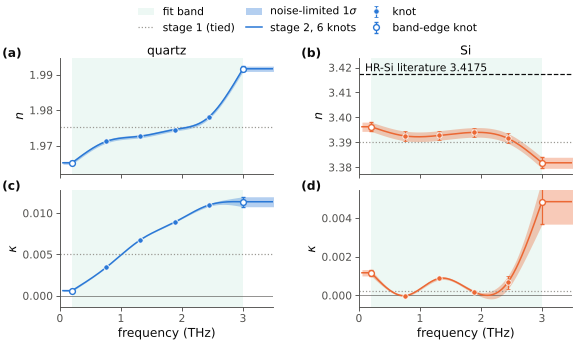

max CR half-width of the bands in the fit band: {'quartz_n': 0.0007450983135917595, 'quartz_k': 0.0006029421151881327, 'Si_n': 0.0022150598383151314, 'Si_k': 0.0011587281230339608}


In [13]:
SHOW_RESID_BAND = False      # True: also draw the CR band scaled by residual RMS / sigma (model-error scale)
f_plot = np.linspace(0.05, 3.5, 400)
with torch.no_grad():
    n_c, k_c = model.nk(f_plot); n_c, k_c = n_c.numpy(), k_c.numpy()
A_plot = interp_basis(f_plot, f_knots, INTERP)
def band(sl):
    C = cov27[sl, sl]; return np.sqrt(np.einsum('ij,jk,ik->i', A_plot, C, A_plot))
bands = {('quartz', 'n'): band(slice(0, 6)), ('quartz', 'k'): band(slice(6, 12)), ('Si', 'n'): band(slice(12, 18)), ('Si', 'k'): band(slice(18, 24))}
kb = {('quartz', 'n'): b27[0:6], ('quartz', 'k'): b27[6:12], ('Si', 'n'): b27[12:18], ('Si', 'k'): b27[18:24]}
RS = rms_disp / sigma_noise
fig, axs = plt.subplots(2, 2, figsize=ps.figsize(1.0, height_cm=8.0), sharex=True,
                        gridspec_kw=dict(hspace=0.14, wspace=0.4, left=0.1, right=0.99, top=0.83, bottom=0.11))
edge = np.array([True, False, False, False, False, True])
for col, (j, nm) in enumerate([(0, 'quartz'), (2, 'Si')]):
    c = ps.ROLE[nm]
    for row, (q, cur, kn, flat) in enumerate([('n', n_c[j], st['n'][j].numpy(), st_flat['n'][j, 0].item()), ('k', k_c[j], st['k'][j].numpy(), st_flat['k'][j, 0].item())]):
        ax = axs[row, col]
        ax.axvspan(F_LO, F_HI, color=ps.AQUA, alpha=0.08, lw=0, label='fit band' if (row, col) == (0, 0) else None)
        if q == 'k': ax.axhline(0, color=ps.INK2, lw=0.4)
        ax.axhline(flat, color=ps.ROLE['stage1'], lw=0.8, ls=':', label='stage 1 (tied)' if (row, col) == (0, 0) else None)
        if SHOW_RESID_BAND:
            ax.fill_between(f_plot, cur - RS * bands[(nm, q)], cur + RS * bands[(nm, q)], color=c, alpha=0.12, lw=0,
                            label=r'noise-limited 1$\sigma$ $\times$ RMS/$\sigma$' if (row, col) == (0, 0) else None)
        ax.fill_between(f_plot, cur - bands[(nm, q)], cur + bands[(nm, q)], color=c, alpha=0.35, lw=0, label=r'noise-limited 1$\sigma$' if (row, col) == (0, 0) else None)
        ax.plot(f_plot, cur, color=c, lw=1.0, label='stage 2, 6 knots' if (row, col) == (0, 0) else None)
        ax.errorbar(f_knots[~edge], kn[~edge], yerr=kb[(nm, q)][~edge], fmt='o', color=c, ms=3.5, mec='white', mew=0.5, elinewidth=0.8, capsize=1.5, zorder=5,
                    label='knot' if (row, col) == (0, 0) else None)
        ax.errorbar(f_knots[edge], kn[edge], yerr=kb[(nm, q)][edge], fmt='o', color=c, ms=3.8, mfc='white', mec=c, mew=0.9, elinewidth=0.8, capsize=1.5, zorder=5,
                    label='band-edge knot' if (row, col) == (0, 0) else None)
        ax.set_ylabel(r'$n$' if q == 'n' else r'$\kappa$')
        if row == 0: ax.set_title(nm, fontsize=8, pad=2)
        if row == 1: ax.set_xlabel('frequency (THz)')
axs[0, 1].axhline(N_SI_LIT, color=ps.INK, lw=0.8, ls='--')
axs[0, 1].text(0.1, N_SI_LIT, 'HR-Si literature 3.4175', fontsize=7, color=ps.INK, va='bottom', ha='left')
def _lim(ax, vals, lo_pad=0.12, hi_pad=0.12):
    lo, hi = float(np.min(vals)), float(np.max(vals)); r = max(hi - lo, 1e-4)
    ax.set_ylim(lo - lo_pad * r, hi + hi_pad * r)
_lim(axs[0, 0], np.r_[n_c[0], st_flat['n'][0, 0].item()]); _lim(axs[0, 1], np.r_[n_c[2], st_flat['n'][2, 0].item(), N_SI_LIT + 0.002])
_lim(axs[1, 0], np.r_[k_c[0], 0.0, st_flat['k'][0, 0].item()]); _lim(axs[1, 1], np.r_[k_c[2], 0.0, st_flat['k'][2, 0].item()])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.53, 1.0), ncol=3, columnspacing=1.0, handlelength=1.5, fontsize=7)
axs[1, 1].set_xlim(0, 3.5)
for a in axs.ravel(): ps.despine(a)
for a, l in zip(axs.ravel(), 'abcd'): ps.panel_label(a, l, x=-0.27, y=0.98)
ps.savefig(fig, '../figs/fig7_qas_nk')
plt.show()
LOOP1['fig7_data'] = dict(cr_band_half_width_max={f'{k[0]}_{k[1]}': float(v[(f_plot >= F_LO) & (f_plot <= F_HI)].max()) for k, v in bands.items()},
                          residual_scale_factor_of_light_band=RS, edge_knots_THz=[float(f_knots[0]), float(f_knots[-1])], n_Si_literature=N_SI_LIT)
print('max CR half-width of the bands in the fit band:', LOOP1['fig7_data']['cr_band_half_width_max'])

# Loop-2 check C16 (run-3 part) — phase and group optical thickness of quartz and Si from the stage-2 knots

In [14]:
from scipy.interpolate import CubicSpline
c16_r3 = {}
for nm, nk, dd in (('quartz', nq, dq), ('Si', ns, ds)):
    cs = CubicSpline(f_knots, nk, bc_type='natural')
    ff = np.array([0.5, 1.0, 1.5, 2.0])
    c16_r3[nm] = dict(d_um=dd * 1e6, f_THz=ff, n_phase=cs(ff), n_group=cs(ff) + ff * cs(ff, 1),
                      nd_phase_um=cs(ff) * dd * 1e6, nd_group_um=(cs(ff) + ff * cs(ff, 1)) * dd * 1e6,
                      nd_phase_1THz_um=float(cs(1.0)) * dd * 1e6, nd_group_1THz_um=float(cs(1.0) + cs(1.0, 1)) * dd * 1e6)
    print(f"run 3 {nm}: d {dd*1e6:.2f} um; n d at 1 THz: phase {c16_r3[nm]['nd_phase_1THz_um']:.1f} um, group {c16_r3[nm]['nd_group_1THz_um']:.1f} um; "
          f"group n d at 0.5/1/1.5/2 THz: " + ', '.join(f'{v:.1f}' for v in c16_r3[nm]['nd_group_um']))
c16_r3['d_q_plus_d_Si_um'] = (dq + ds) * 1e6
c16_r3['stage1_flat'] = dict(nd_quartz_um=st_flat['n'][0, 0].item() * st_flat['d'][0].item() * 1e6, nd_Si_um=st_flat['n'][2, 0].item() * st_flat['d'][2].item() * 1e6)
results['loop2_checks'] = dict(date='2026-11-24', source='reviews/loop2_domain.md',
                               C16_run3_optical_thickness=dict(note='stage-2 knots, natural cubic spline; group index n + f dn/df', **c16_r3))

run 3 quartz: d 976.63 um; n d at 1 THz: phase 1926.0 um, group 1928.2 um; group n d at 0.5/1/1.5/2 THz: 1928.3, 1928.2, 1932.2, 1934.2
run 3 Si: d 388.91 um; n d at 1 THz: phase 1319.3 um, group 1319.4 um; group n d at 0.5/1/1.5/2 THz: 1318.6, 1319.4, 1321.3, 1319.3


# Loop-3: C15 (knot correlations, ripple significance, knot-grid resolution) and the note on σ of run 3

In [15]:
def offdiag(blk):
    C = corr27[blk, blk]; m = ~np.eye(C.shape[0], dtype=bool); return float(C[m].min()), float(C[m].mean())
c15 = dict(knot_correlations={})
for nm, sl in (('Si_n', slice(12, 18)), ('quartz_n', slice(0, 6)), ('Si_k', slice(18, 24)), ('quartz_k', slice(6, 12))):
    mn, me = offdiag(sl); C = corr27[sl, sl]
    c15['knot_correlations'][nm] = dict(min_offdiag=mn, mean_offdiag=me, matrix=C,
                                        min_offdiag_interior_and_low_edge=offdiag(slice(sl.start, sl.stop - 1))[0])
    print(f"{nm:9s} knot-knot correlation: min {mn:+.3f}, mean {me:+.3f} (without the 3-THz knot: min {c15['knot_correlations'][nm]['min_offdiag_interior_and_low_edge']:+.3f})")
# alternating contrast of the four interior knots, c = (k1 - k2 + k3 - k4)/4 (knots 0.76, 1.32, 1.88, 2.44 THz)
RS = rms_disp / sigma_noise
c15['ripple'] = {}
for nm, off, vals in (('Si_n', 12, ns), ('Si_k', 18, ks)):
    g = np.zeros(27); g[off + 1:off + 5] = np.array([1, -1, 1, -1]) / 4
    val = float(g @ theta0); bd = lin(g)
    c15['ripple'][nm] = dict(definition='(x_0.76 - x_1.32 + x_1.88 - x_2.44) / 4', value=val, bound_prepulse=bd, value_over_bound_prepulse=abs(val) / bd,
                             bound_residual_scaled=bd * RS, value_over_bound_residual_scaled=abs(val) / (bd * RS), residual_scale_factor=RS)
    print(f"{nm} interior alternating contrast {val:+.2e} +- {bd:.1e}: {abs(val)/bd:.1f} pre-pulse bounds, {abs(val)/(bd*RS):.2f} residual-scaled bounds")
dfk = float(f_knots[1] - f_knots[0])
c15['knot_grid'] = dict(spacing_THz=dfk, shortest_resolvable_period_THz=2 * dfk, gap_free_spectral_range_THz=299792458.0 / (2 * da) / 1e12)
print(f"knot spacing {dfk:.2f} THz -> shortest period {2*dfk:.2f} THz; air-gap FSR c/2d_air = {c15['knot_grid']['gap_free_spectral_range_THz']:.2f} THz")
results['loop2_checks']['C15_knot_correlations_and_ripple'] = c15

# σ of run 3 versus the Sec. 5 trace: facts from the file headers and the C14 noise table (nb2.json)
c14 = json.load(open('../results/nb2.json'))['loop1_checks']['C14_noise_table']['traces']
hdr = lambda f: [l for l in open(f) if 'Average over' in l][0].split('Average over')[1].split('waveforms')[0].strip()
qs, r3 = c14['quartzSi_sample'], c14['run3_sample']
results['loop2_checks']['sigma_note'] = dict(
    text=(f"Run 3 (Sec. 8) averages {hdr('../data/quartz_air_silicon_15_min_3.txt')} waveforms over a {t_r[-1]:.0f} ps window; the Sec. 5 trace averages "
          f"{hdr('../data/Quartz_Si_15min_nitrogen.txt')} waveforms over 80 ps. Its pre-pulse std (first 10 ps) is {r3['std_0_10ps']:.1e} vs {qs['std_0_10ps']:.1e} "
          f"because two 2-ps segments of its pre-pulse carry bursts (std {r3['segments'][2]['std']:.1e} at 4-6 ps and {r3['segments'][4]['std']:.1e} at 8-10 ps; "
          f"other segments {min(s_['std'] for s_ in r3['segments']):.1e}-{sorted(s_['std'] for s_ in r3['segments'])[2]:.1e}); its white (first-difference) level is lower, "
          f"{r3['white_min']:.1e} vs {qs['white_min']:.1e}."),
    run3=dict(waveforms=int(hdr('../data/quartz_air_silicon_15_min_3.txt')), window_ps=float(t_r[-1]), std_0_10ps=r3['std_0_10ps'], white_min=r3['white_min'],
              segment_std=[s_['std'] for s_ in r3['segments']]),
    sec5=dict(waveforms=int(hdr('../data/Quartz_Si_15min_nitrogen.txt')), window_ps=80.0, std_0_10ps=qs['std_0_10ps'], white_min=qs['white_min'],
              segment_std=[s_['std'] for s_ in qs['segments']]))
print(results['loop2_checks']['sigma_note']['text'])

Si_n      knot-knot correlation: min +0.847, mean +0.946 (without the 3-THz knot: min +0.984)
quartz_n  knot-knot correlation: min +0.569, mean +0.838 (without the 3-THz knot: min +0.929)
Si_k      knot-knot correlation: min -0.189, mean +0.067 (without the 3-THz knot: min -0.189)
quartz_k  knot-knot correlation: min -0.044, mean +0.119 (without the 3-THz knot: min -0.036)
Si_n interior alternating contrast +5.45e-04 +- 9.4e-05: 5.8 pre-pulse bounds, 0.90 residual-scaled bounds
Si_k interior alternating contrast -3.43e-04 +- 9.3e-05: 3.7 pre-pulse bounds, 0.58 residual-scaled bounds
knot spacing 0.56 THz -> shortest period 1.12 THz; air-gap FSR c/2d_air = 1.19 THz
Run 3 (Sec. 8) averages 3000 waveforms over a 115 ps window; the Sec. 5 trace averages 1000 waveforms over 80 ps. Its pre-pulse std (first 10 ps) is 9.0e-04 vs 2.9e-04 because two 2-ps segments of its pre-pulse carry bursts (std 1.1e-03 at 4-6 ps and 1.7e-03 at 8-10 ps; other segments 6.9e-05-1.7e-04); its white (first-differ

In [16]:
LOOP1['timings_s'] = T_LOOP1
LOOP1['figure_export'] = ps.FONT_LOG
results['loop1_checks'] = LOOP1
json.dump(ps.to_jsonable(results), open('../results/nb5.json', 'w'), indent=1)
print('wrote ../results/nb5.json with loop1_checks:', list(LOOP1))

wrote ../results/nb5.json with loop1_checks: ['date', 'source', 'C12_cramer_rao_and_profiles', 'C2_run3_no_hinge', 'C13_Si_tied', 'fig7_data', 'timings_s', 'figure_export']
